***DATASET*** ***IMPORTING***

In [ ]:
# from google.colab import files

# uploaded = files.upload()

Saving PlantDisease416x416.zip to PlantDisease416x416.zip


In [3]:
'PlantDisease416x416.zip'

'PlantDisease416x416.zip'

In [4]:
import os

print(os.listdir("/content"))

['.config', 'PlantDisease416x416.zip', 'sample_data']


In [7]:
'PlantDisease416x416.zip'

'PlantDisease416x416.zip'

In [8]:
from pathlib import Path

zip_path = Path("/content/PlantDisease416x416.zip")

print("Dataset found:", zip_path.exists())
print("Dataset path:", zip_path)

Dataset found: True
Dataset path: /content/PlantDisease416x416.zip


***DATA PREPROCESSING **


In [17]:
!pip install pillow pyyaml ultralytics -q

In [1]:
import os
import zipfile
import shutil
import json
import yaml
from pathlib import Path
from PIL import Image, ImageOps, UnidentifiedImageError
from collections import Counter, defaultdict
import random

ModuleNotFoundError: No module named 'yaml'

In [20]:
ZIP_PATH = Path("/content/PlantDisease416x416.zip")
EXTRACT_DIR = Path("/content/extracted_dataset")
OUTPUT_DIR = Path("/content/plant_disease_yolo_clean")

IMAGE_SIZE = 416
VAL_RATIO = 0.2
SEED = 42
DROP_EMPTY_LABELS = True

In [21]:
if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

DATASET_ROOT = EXTRACT_DIR / "PlantDisease416x416"

train_dir = DATASET_ROOT / "train"
test_dir = DATASET_ROOT / "test"

print("Dataset extracted successfully")
print("Train folder:", train_dir)
print("Test folder:", test_dir)

Dataset extracted successfully
Train folder: /content/extracted_dataset/PlantDisease416x416/train
Test folder: /content/extracted_dataset/PlantDisease416x416/test


In [22]:
def read_classes(split_dir):
    labels_file = split_dir / "_darknet.labels"
    class_names = []

    with open(labels_file, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                class_names.append(line.strip())

    return class_names


class_names = read_classes(train_dir)

print("Total classes:", len(class_names))
class_names

Total classes: 30


['Apple Scab Leaf',
 'Apple leaf',
 'Apple rust leaf',
 'Bell_pepper leaf',
 'Bell_pepper leaf spot',
 'Blueberry leaf',
 'Cherry leaf',
 'Corn Gray leaf spot',
 'Corn leaf blight',
 'Corn rust leaf',
 'Peach leaf',
 'Potato leaf',
 'Potato leaf early blight',
 'Potato leaf late blight',
 'Raspberry leaf',
 'Soyabean leaf',
 'Soybean leaf',
 'Squash Powdery mildew leaf',
 'Strawberry leaf',
 'Tomato Early blight leaf',
 'Tomato Septoria leaf spot',
 'Tomato leaf',
 'Tomato leaf bacterial spot',
 'Tomato leaf late blight',
 'Tomato leaf mosaic virus',
 'Tomato leaf yellow virus',
 'Tomato mold leaf',
 'Tomato two spotted spider mites leaf',
 'grape leaf',
 'grape leaf black rot']

**DATA CLEANING**

In [23]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def clean_image(src, dst, image_size=416):
    try:
        with Image.open(src) as img:
            img.verify()

        with Image.open(src) as img:
            img = ImageOps.exif_transpose(img).convert("RGB")
            img = img.resize((image_size, image_size), Image.Resampling.LANCZOS)

            dst.parent.mkdir(parents=True, exist_ok=True)
            img.save(dst, format="JPEG", quality=95)

        return True, ""

    except (OSError, UnidentifiedImageError) as e:
        return False, str(e)


def clean_label(src, dst, class_count):
    valid_lines = []
    errors = []

    if not src.exists():
        errors.append("Missing label file")
        return valid_lines, errors

    with open(src, "r", encoding="utf-8") as f:
        lines = f.readlines()

    for line_number, line in enumerate(lines, start=1):
        line = line.strip()

        if not line:
            continue

        parts = line.split()

        if len(parts) != 5:
            errors.append(f"Line {line_number}: Invalid YOLO format")
            continue

        try:
            class_id = int(float(parts[0]))
            x, y, w, h = map(float, parts[1:])
        except ValueError:
            errors.append(f"Line {line_number}: Non-numeric value")
            continue

        if class_id < 0 or class_id >= class_count:
            errors.append(f"Line {line_number}: Class ID out of range")
            continue

        if not all(0 <= value <= 1 for value in [x, y, w, h]):
            errors.append(f"Line {line_number}: Bounding box values outside 0-1")
            continue

        if w <= 0 or h <= 0:
            errors.append(f"Line {line_number}: Width or height is zero")
            continue

        valid_lines.append(f"{class_id} {x:.6f} {y:.6f} {w:.6f} {h:.6f}")

    dst.parent.mkdir(parents=True, exist_ok=True)

    with open(dst, "w", encoding="utf-8") as f:
        f.write("\n".join(valid_lines))

    return valid_lines, errors


def main_class(label_lines):
    if not label_lines:
        return -1

    class_ids = [int(line.split()[0]) for line in label_lines]
    return Counter(class_ids).most_common(1)[0][0]

**DATA SPILITING**

In [24]:
def process_split(source_dir, staging_dir, class_count):
    records = []

    report = {
        "images_seen": 0,
        "images_kept": 0,
        "bad_images": [],
        "empty_labels": [],
        "label_errors": []
    }

    for image_path in sorted(source_dir.iterdir()):
        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        report["images_seen"] += 1

        label_path = image_path.with_suffix(".txt")

        output_image = staging_dir / "images" / image_path.name
        output_label = staging_dir / "labels" / f"{image_path.stem}.txt"

        image_ok, image_error = clean_image(image_path, output_image, IMAGE_SIZE)

        if not image_ok:
            report["bad_images"].append({
                "image": str(image_path),
                "error": image_error
            })
            continue

        label_lines, label_errors = clean_label(label_path, output_label, class_count)

        if label_errors:
            report["label_errors"].append({
                "label": str(label_path),
                "errors": label_errors
            })

        if not label_lines:
            report["empty_labels"].append(str(label_path))

            if DROP_EMPTY_LABELS:
                output_image.unlink(missing_ok=True)
                output_label.unlink(missing_ok=True)
                continue

        records.append({
            "image": output_image,
            "label": output_label,
            "main_class": main_class(label_lines),
            "boxes": len(label_lines)
        })

        report["images_kept"] += 1

    return records, report

In [25]:
def split_train_val(records, val_ratio=0.2, seed=42):
    random.seed(seed)

    by_class = defaultdict(list)

    for record in records:
        by_class[record["main_class"]].append(record)

    train_records = []
    val_records = []

    for class_id, class_records in by_class.items():
        random.shuffle(class_records)

        val_count = round(len(class_records) * val_ratio)

        if len(class_records) > 1:
            val_count = max(1, val_count)
        else:
            val_count = 0

        val_records.extend(class_records[:val_count])
        train_records.extend(class_records[val_count:])

    random.shuffle(train_records)
    random.shuffle(val_records)

    return train_records, val_records

In [28]:
def copy_records(records, output_dir, split):
    image_output = output_dir / "images" / split
    label_output = output_dir / "labels" / split

    image_output.mkdir(parents=True, exist_ok=True)
    label_output.mkdir(parents=True, exist_ok=True)

    for record in records:
        shutil.copy2(record["image"], image_output / record["image"].name)
        shutil.copy2(record["label"], label_output / record["label"].name)

In [29]:
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

staging_dir = OUTPUT_DIR / "_staging"
staging_dir.mkdir(parents=True, exist_ok=True)

train_records_all, train_report = process_split(
    train_dir,
    staging_dir / "train_raw",
    len(class_names)
)

test_records, test_report = process_split(
    test_dir,
    staging_dir / "test_raw",
    len(class_names)
)

train_records, val_records = split_train_val(
    train_records_all,
    val_ratio=VAL_RATIO,
    seed=SEED
)

copy_records(train_records, OUTPUT_DIR, "train")
copy_records(val_records, OUTPUT_DIR, "val")
copy_records(test_records, OUTPUT_DIR, "test")

shutil.rmtree(staging_dir, ignore_errors=True)

print("Preprocessing completed")
print("Train images:", len(train_records))
print("Validation images:", len(val_records))
print("Test images:", len(test_records))

Preprocessing completed
Train images: 1855
Validation images: 463
Test images: 238


In [30]:
data_yaml = {
    "path": str(OUTPUT_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(class_names),
    "names": class_names
}

yaml_path = OUTPUT_DIR / "data.yaml"

with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print("data.yaml created:")
print(yaml_path)

data.yaml created:
/content/plant_disease_yolo_clean/data.yaml


In [31]:
report = {
    "classes": class_names,
    "class_count": len(class_names),
    "train_images": len(train_records),
    "val_images": len(val_records),
    "test_images": len(test_records),
    "train_report": train_report,
    "test_report": test_report
}

report_path = OUTPUT_DIR / "preprocessing_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("Report saved:")
print(report_path)

Report saved:
/content/plant_disease_yolo_clean/preprocessing_report.json


In [32]:
for split in ["train", "val", "test"]:
    image_count = len(list((OUTPUT_DIR / "images" / split).glob("*")))
    label_count = len(list((OUTPUT_DIR / "labels" / split).glob("*")))

    print(split)
    print("Images:", image_count)
    print("Labels:", label_count)
    print()

train
Images: 1855
Labels: 1855

val
Images: 463
Labels: 463

test
Images: 238
Labels: 238



**CHECKING OF PREPROCESSED DATA **

In [1]:
!pip install ultralytics -q
from ultralytics import YOLO
from pathlib import Path
import yaml
import shutil # Added for rmtree
import zipfile # Added for zipfile.ZipFile

# Redefine necessary variables and functions for class_names
# Define ZIP_PATH here to be self-contained
ZIP_PATH = Path("/content/PlantDisease416x416.zip") # Added

EXTRACT_DIR = Path("/content/extracted_dataset")

# Re-extract the dataset to ensure files are present
if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

DATASET_ROOT = EXTRACT_DIR / "PlantDisease416x416"
train_dir = DATASET_ROOT / "train"

def read_classes(split_dir):
    labels_file = split_dir / "_darknet.labels"
    class_names = []
    with open(labels_file, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                class_names.append(line.strip())
    return class_names

# Corrected to use train_dir for reading class names
class_names = read_classes(train_dir)

model = YOLO("yolov8n.pt")

OUTPUT_DIR = Path("/content/plant_disease_yolo_clean")
yaml_path = OUTPUT_DIR / "data.yaml"

# Re-create data.yaml to ensure it exists
data_yaml = {
    "path": str(OUTPUT_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(class_names),
    "names": class_names
}

with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print(f"Re-created data.yaml at: {yaml_path}")

model.train(
    data=str(yaml_path),
    epochs=1,
    imgsz=416,
    batch=16,
    name="plant_disease_detection"
)

'pip' is not recognized as an internal or external command,
operable program or batch file.


ModuleNotFoundError: No module named 'ultralytics'

*DOWNLOADING PREPROCESSED DATA *

In [37]:
shutil.make_archive("/content/plant_disease_yolo_clean", "zip", OUTPUT_DIR)

files.download("/content/plant_disease_yolo_clean.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**TRAINING**

Install Libraries

In [38]:
!pip install ultralytics opencv-python pandas matplotlib pyyaml -q

Upload Your Preprocessed Dataset

In [39]:
from google.colab import files

uploaded = files.upload()

Saving plant_disease_yolo_clean.zip to plant_disease_yolo_clean (1).zip


plant_disease_yolo_clean.zip

**DATA EXTRACTION**

In [40]:
import zipfile
import shutil
from pathlib import Path

ZIP_PATH = Path("/content/plant_disease_yolo_clean.zip")
EXTRACT_DIR = Path("/content/plant_disease_dataset")

if not ZIP_PATH.exists():
    zip_files = list(Path("/content").glob("*.zip"))
    if len(zip_files) == 0:
        raise FileNotFoundError("No zip file uploaded.")
    ZIP_PATH = zip_files[0]

if EXTRACT_DIR.exists():
    shutil.rmtree(EXTRACT_DIR)

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Extracted files:")
for item in EXTRACT_DIR.iterdir():
    print(item)

Extracted files:
/content/plant_disease_dataset/preprocessing_report.json
/content/plant_disease_dataset/labels
/content/plant_disease_dataset/images
/content/plant_disease_dataset/data.yaml


In [41]:
import os

yaml_files = list(EXTRACT_DIR.rglob("data.yaml"))

if len(yaml_files) == 0:
    raise FileNotFoundError("data.yaml not found inside dataset zip.")

yaml_path = yaml_files[0]

print("Using data.yaml:")
print(yaml_path)

Using data.yaml:
/content/plant_disease_dataset/data.yaml


***Train Plant Disease Detection Model***



In [42]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

train_results = model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=416,
    batch=16,
    name="plant_disease_detection",
    patience=10
)

Ultralytics 8.4.53 🚀 Python-3.12.13 torch-2.10.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/plant_disease_dataset/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=plant_disease_detection-5, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, o

In [43]:
from pathlib import Path

best_models = list(Path("/content/runs").rglob("best.pt"))

if len(best_models) == 0:
    raise FileNotFoundError("best.pt not found. Training may not have completed.")

trained_model_path = best_models[-1]

print("Best model path:")
print(trained_model_path)

Best model path:
/content/runs/detect/plant_disease_detection-4/weights/best.pt


In [44]:
model = YOLO(str(trained_model_path))

metrics = model.val(data=str(yaml_path))

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.53 🚀 Python-3.12.13 torch-2.10.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,011,498 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 981.1±411.0 MB/s, size: 41.1 KB)
val: Scanning /content/plant_disease_yolo_clean/labels/val.cache... 463 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 463/463 97.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 1.9s/it 55.8s
                   all        463       1708     0.0212      0.412     0.0347     0.0265
       Apple Scab Leaf         17         31      0.018      0.677     0.0203     0.0143
            Apple leaf         16         23     0.0169      0.696     0.0184     0.0137
       Apple rust leaf         16         28     0.0117      0.286    0.00351    0.00229
      Bell_pepper leaf         11         64     0.0262      0.344     0.0133    0.00945
 Bell_pepper leaf spot         12

In [45]:
import pandas as pd
import matplotlib.pyplot as plt

results_csv_files = list(Path("/content/runs").rglob("results.csv"))

if len(results_csv_files) == 0:
    raise FileNotFoundError("results.csv not found.")

results_csv = results_csv_files[-1]

df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()

df.head()

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,771.706,1.37548,4.43409,1.47207,0.02116,0.41122,0.03477,0.0265,1.31214,4.21739,1.39382,0.000097,0.000097,0.000097


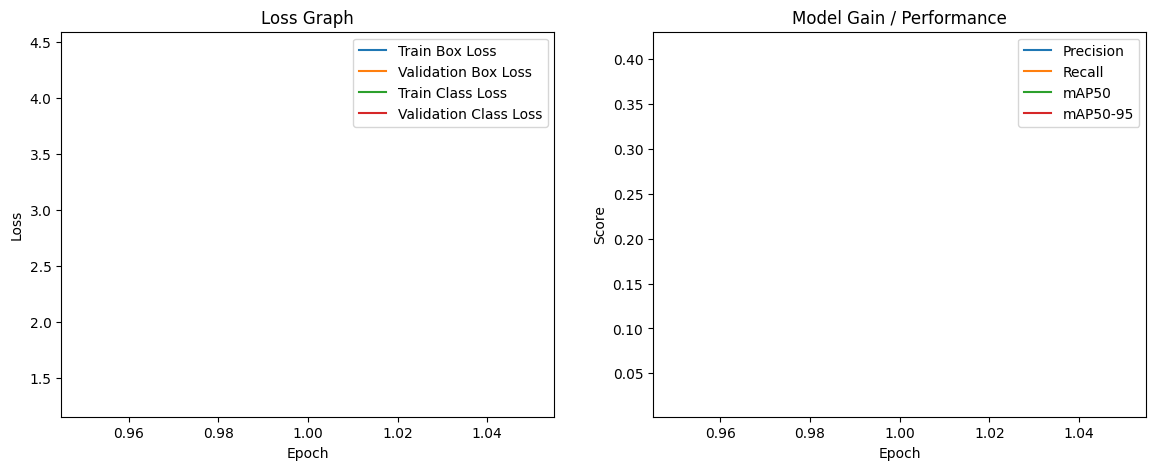

In [46]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(df["epoch"], df["train/box_loss"], label="Train Box Loss")
plt.plot(df["epoch"], df["val/box_loss"], label="Validation Box Loss")
plt.plot(df["epoch"], df["train/cls_loss"], label="Train Class Loss")
plt.plot(df["epoch"], df["val/cls_loss"], label="Validation Class Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Graph")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(df["epoch"], df["metrics/precision(B)"], label="Precision")
plt.plot(df["epoch"], df["metrics/recall(B)"], label="Recall")
plt.plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
plt.plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Model Gain / Performance")
plt.legend()

plt.show()

In [47]:
from google.colab import files
from pathlib import Path

uploaded_image = files.upload()

if len(uploaded_image) == 0:
    raise FileNotFoundError("No image uploaded.")

image_name = list(uploaded_image.keys())[0]
image_path = Path("/content") / image_name

print("Image uploaded:", image_path)

Saving testImage416_2.jpg to testImage416_2.jpg
Image uploaded: /content/testImage416_2.jpg


In [48]:
from google.colab import files
from pathlib import Path

uploaded_image = files.upload()

if len(uploaded_image) == 0:
    raise FileNotFoundError("No image uploaded.")

image_name = list(uploaded_image.keys())[0]
image_path = Path("/content") / image_name

print("Image uploaded:", image_path)

Saving testImage416_8.jpg to testImage416_8.jpg
Image uploaded: /content/testImage416_8.jpg


In [49]:
from google.colab import files
from pathlib import Path

uploaded_image = files.upload()

if len(uploaded_image) == 0:
    raise FileNotFoundError("No image uploaded.")

image_name = list(uploaded_image.keys())[0]
image_path = Path("/content") / image_name

print("Image uploaded:", image_path)

Saving testImage416_12.jpg to testImage416_12.jpg
Image uploaded: /content/testImage416_12.jpg


In [50]:
from google.colab import files
from pathlib import Path

uploaded_image = files.upload()

if len(uploaded_image) == 0:
    raise FileNotFoundError("No image uploaded.")

image_name = list(uploaded_image.keys())[0]
image_path = Path("/content") / image_name

print("Image uploaded:", image_path)

Saving testImage416_41.jpg to testImage416_41.jpg
Image uploaded: /content/testImage416_41.jpg


In [51]:
from google.colab import files
from pathlib import Path

uploaded_image = files.upload()

if len(uploaded_image) == 0:
    raise FileNotFoundError("No image uploaded.")

image_name = list(uploaded_image.keys())[0]
image_path = Path("/content") / image_name

print("Image uploaded:", image_path)

Saving testImage416_66.jpg to testImage416_66.jpg
Image uploaded: /content/testImage416_66.jpg


In [52]:
from google.colab import files
from pathlib import Path

uploaded_image = files.upload()

if len(uploaded_image) == 0:
    raise FileNotFoundError("No image uploaded.")

image_name = list(uploaded_image.keys())[0]
image_path = Path("/content") / image_name

print("Image uploaded:", image_path)

Saving testImage416_104.jpg to testImage416_104.jpg
Image uploaded: /content/testImage416_104.jpg


In [53]:
from google.colab import files
from pathlib import Path

uploaded_image = files.upload()

if len(uploaded_image) == 0:
    raise FileNotFoundError("No image uploaded.")

image_name = list(uploaded_image.keys())[0]
image_path = Path("/content") / image_name

print("Image uploaded:", image_path)

Saving testImage416_219.jpg to testImage416_219.jpg
Image uploaded: /content/testImage416_219.jpg


In [54]:
from google.colab import files
from pathlib import Path

uploaded_image = files.upload()

if len(uploaded_image) == 0:
    raise FileNotFoundError("No image uploaded.")

image_name = list(uploaded_image.keys())[0]
image_path = Path("/content") / image_name

print("Image uploaded:", image_path)

Saving testImage416_239.jpg to testImage416_239.jpg
Image uploaded: /content/testImage416_239.jpg


In [55]:
prediction = model.predict(
    source=str(image_path),
    imgsz=416,
    conf=0.25,
    save=True,
    project="/content/predictions",
    name="uploaded_image_result",
    exist_ok=True
)

print("Prediction completed.")


image 1/1 /content/testImage416_239.jpg: 416x416 (no detections), 119.7ms
Speed: 1.8ms preprocess, 119.7ms inference, 1.3ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/predictions/uploaded_image_result
Prediction completed.


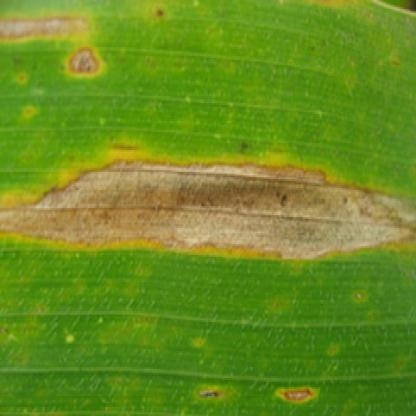

In [56]:
from IPython.display import Image, display
import glob
import os

predicted_images = glob.glob("/content/predictions/uploaded_image_result/*")

image_files = [
    file for file in predicted_images
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
]

if len(image_files) == 0:
    print("No prediction image found.")
else:
    latest_image = max(image_files, key=os.path.getctime)
    display(Image(filename=latest_image))

In [57]:
from google.colab import files
from pathlib import Path

uploaded_images = files.upload()

if len(uploaded_images) == 0:
    raise FileNotFoundError("No images uploaded.")

image_paths = []

for image_name in uploaded_images.keys():
    image_path = Path("/content") / image_name
    image_paths.append(str(image_path))

print("Uploaded images:")
for path in image_paths:
    print(path)

Saving testImage416_2.jpg to testImage416_2 (1).jpg
Saving testImage416_8.jpg to testImage416_8 (1).jpg
Saving testImage416_12.jpg to testImage416_12 (1).jpg
Saving testImage416_41.jpg to testImage416_41 (1).jpg
Saving testImage416_66.jpg to testImage416_66 (1).jpg
Saving testImage416_104.jpg to testImage416_104 (1).jpg
Saving testImage416_219.jpg to testImage416_219 (1).jpg
Saving testImage416_239.jpg to testImage416_239 (1).jpg
Uploaded images:
/content/testImage416_2 (1).jpg
/content/testImage416_8 (1).jpg
/content/testImage416_12 (1).jpg
/content/testImage416_41 (1).jpg
/content/testImage416_66 (1).jpg
/content/testImage416_104 (1).jpg
/content/testImage416_219 (1).jpg
/content/testImage416_239 (1).jpg


In [58]:
prediction = model.predict(
    source=image_paths,
    imgsz=416,
    conf=0.25,
    save=True,
    project="/content/predictions",
    name="uploaded_image_result",
    exist_ok=True
)

print("Prediction completed for", len(image_paths), "images.")


0: 416x416 (no detections), 182.2ms
1: 416x416 (no detections), 182.2ms
2: 416x416 (no detections), 182.2ms
3: 416x416 (no detections), 182.2ms
4: 416x416 (no detections), 182.2ms
5: 416x416 (no detections), 182.2ms
6: 416x416 (no detections), 182.2ms
7: 416x416 (no detections), 182.2ms
Speed: 4.8ms preprocess, 182.2ms inference, 0.6ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/predictions/uploaded_image_result
Prediction completed for 8 images.


Total prediction images: 9
Showing: /content/predictions/uploaded_image_result/testImage416_239.jpg


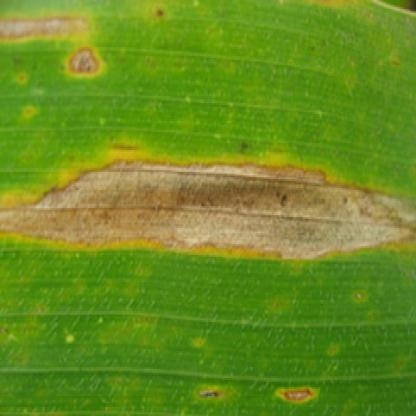

Showing: /content/predictions/uploaded_image_result/image0.jpg


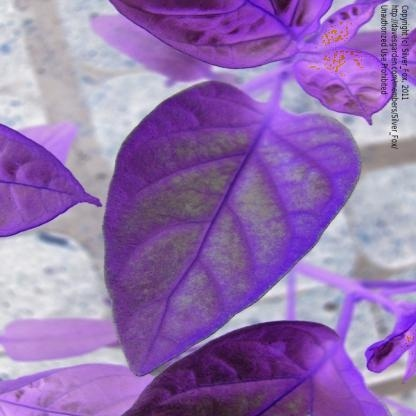

Showing: /content/predictions/uploaded_image_result/image1.jpg


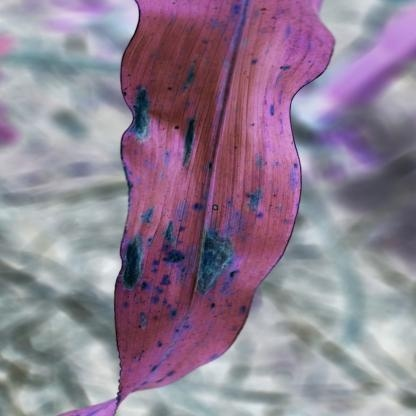

Showing: /content/predictions/uploaded_image_result/image2.jpg


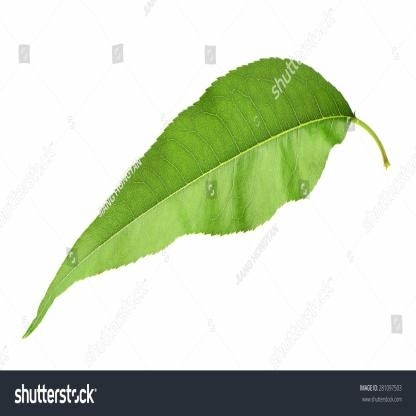

Showing: /content/predictions/uploaded_image_result/image3.jpg


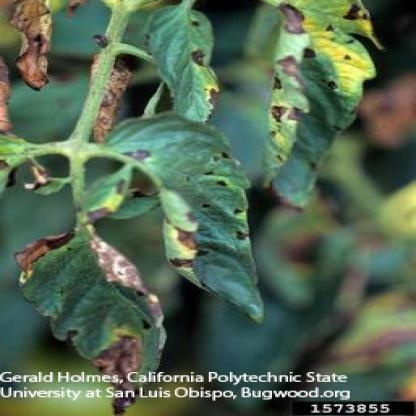

Showing: /content/predictions/uploaded_image_result/image4.jpg


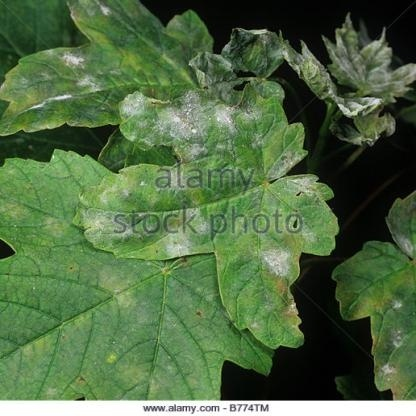

Showing: /content/predictions/uploaded_image_result/image5.jpg


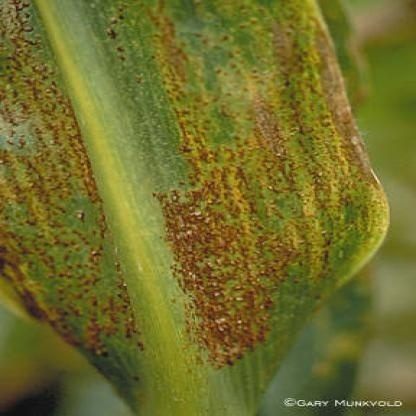

Showing: /content/predictions/uploaded_image_result/image6.jpg


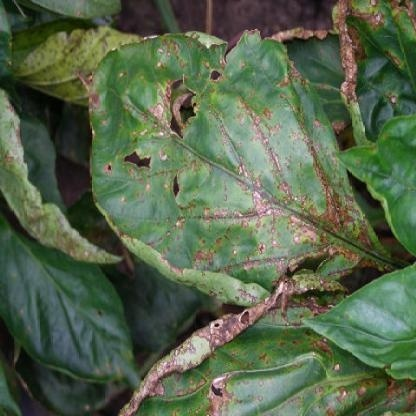

Showing: /content/predictions/uploaded_image_result/image7.jpg


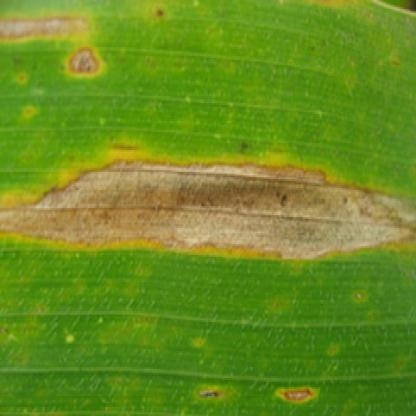

In [59]:
from IPython.display import Image, display
import glob
import os

prediction_folder = "/content/predictions/uploaded_image_result"

predicted_files = glob.glob(prediction_folder + "/*")

image_files = [
    file for file in predicted_files
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
]

if len(image_files) == 0:
    print("No prediction images found.")
else:
    image_files = sorted(image_files, key=os.path.getctime)

    print("Total prediction images:", len(image_files))

    for image_file in image_files:
        print("Showing:", image_file)
        display(Image(filename=image_file))

In [60]:
from google.colab import files
from pathlib import Path

uploaded_images = files.upload()

if len(uploaded_images) == 0:
    raise FileNotFoundError("No images uploaded.")

image_paths = []

for image_name in uploaded_images.keys():
    image_path = Path("/content") / image_name
    image_paths.append(str(image_path))

print("Uploaded images:")
for path in image_paths:
    print(path)

Saving plant_disease_yolo_clean (1).zip to plant_disease_yolo_clean (1) (1).zip
Uploaded images:
/content/plant_disease_yolo_clean (1) (1).zip


In [62]:
from pathlib import Path

# Choose which split you want to predict
# Options: train, val, test
split = "test"

image_folder = Path("/content/plant_disease_dataset/plant_disease_yolo_clean/images") / split

# If your zip extracted with a slightly different root, find images folder automatically
if not image_folder.exists():
    possible_folders = list(Path("/content").rglob(f"images/{split}"))

    if len(possible_folders) == 0:
        raise FileNotFoundError(f"No images/{split} folder found.")

    image_folder = possible_folders[0]

print("Predicting images from:", image_folder)
print("Total images:", len(list(image_folder.glob('*'))))

Predicting images from: /content/plant_disease_dataset/images/test
Total images: 238


In [63]:
dataset_prediction = model.predict(
    source=str(image_folder),
    imgsz=416,
    conf=0.25,
    save=True,
    project="/content/predictions",
    name=f"{split}_dataset_result",
    exist_ok=True
)

print("Prediction completed.")


image 1/238 /content/plant_disease_dataset/images/test/testImage416_1.jpg: 416x416 (no detections), 135.8ms
image 2/238 /content/plant_disease_dataset/images/test/testImage416_10.jpg: 416x416 (no detections), 99.8ms
image 3/238 /content/plant_disease_dataset/images/test/testImage416_100.jpg: 416x416 (no detections), 100.2ms
image 4/238 /content/plant_disease_dataset/images/test/testImage416_101.jpg: 416x416 (no detections), 99.8ms
image 5/238 /content/plant_disease_dataset/images/test/testImage416_102.jpg: 416x416 (no detections), 98.9ms
image 6/238 /content/plant_disease_dataset/images/test/testImage416_103.jpg: 416x416 (no detections), 100.5ms
image 7/238 /content/plant_disease_dataset/images/test/testImage416_104.jpg: 416x416 (no detections), 100.7ms
image 8/238 /content/plant_disease_dataset/images/test/testImage416_105.jpg: 416x416 (no detections), 116.6ms
image 9/238 /content/plant_disease_dataset/images/test/testImage416_106.jpg: 416x416 (no detections), 102.4ms
image 10/238 /c

In [64]:
from pathlib import Path

all_image_folders = []

for split in ["train", "val", "test"]:
    folders = list(Path("/content").rglob(f"images/{split}"))

    if len(folders) > 0:
        all_image_folders.append(folders[0])

print("Image folders found:")
for folder in all_image_folders:
    print(folder)

Image folders found:
/content/plant_disease_dataset/images/train
/content/plant_disease_dataset/images/val
/content/plant_disease_dataset/images/test


In [65]:
all_dataset_predictions = []

for folder in all_image_folders:
    split_name = folder.name

    preds = model.predict(
        source=str(folder),
        imgsz=416,
        conf=0.25,
        save=True,
        project="/content/predictions",
        name=f"{split_name}_dataset_result",
        exist_ok=True
    )

    all_dataset_predictions.extend(preds)

print("Prediction completed for all dataset splits.")
print("Total prediction results:", len(all_dataset_predictions))


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/1855 /content/plant_disease_dataset/images/train/Image416_1.jpg: 416x416 (no detections), 112.4ms
image 2/1855 /content/plant_disease_dataset/images/train/Image416_10.jpg: 416x416 (no detections), 105.1ms
image 3/1855 /content/plant_disease_dataset/images/train/Image416_100.jpg: 416x416 (no detections), 100.0ms
image 4/1855 /content/plant_disease_dataset/images/train/Image416_1000.jpg: 416x416 (no detections), 98.1ms
image 5/1855 /content/plant_d

Total saved prediction images: 2565


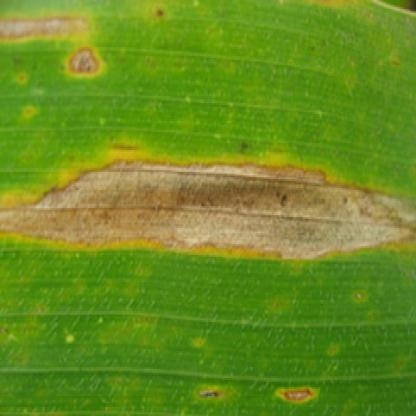

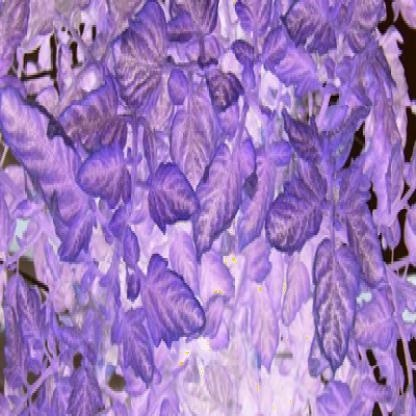

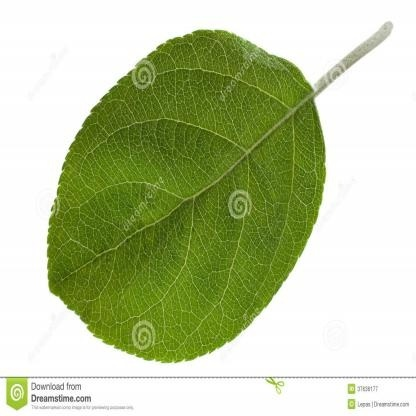

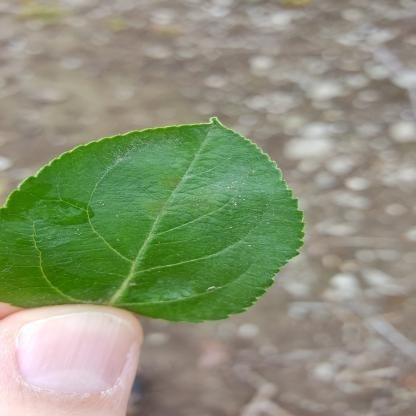

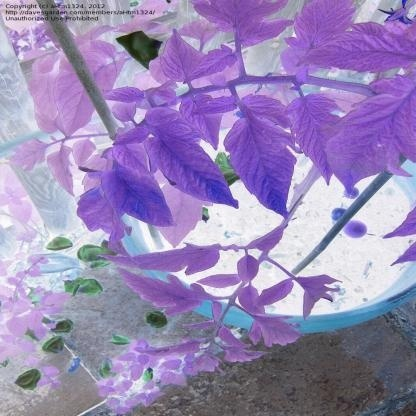

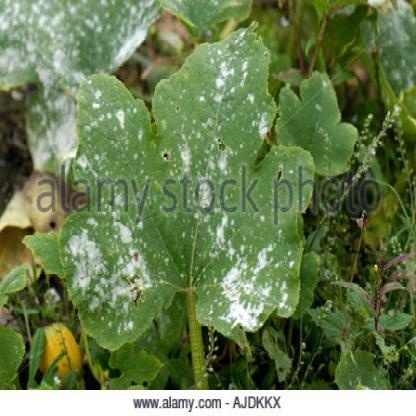

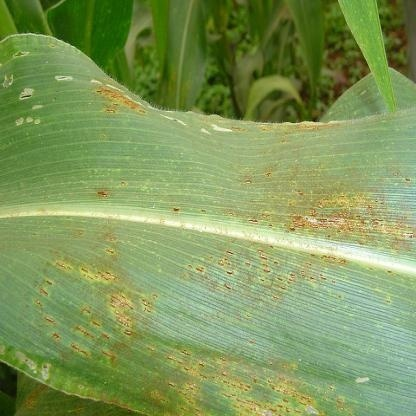

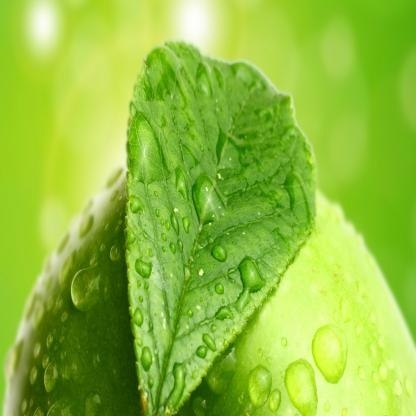

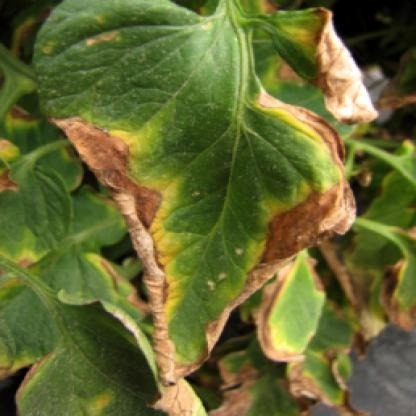

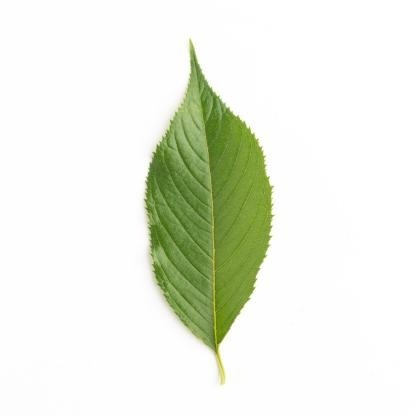

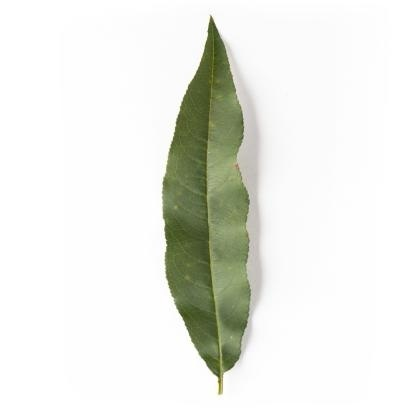

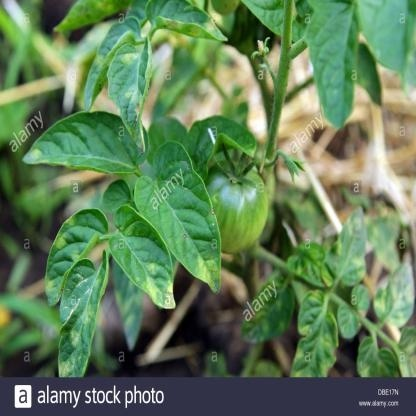

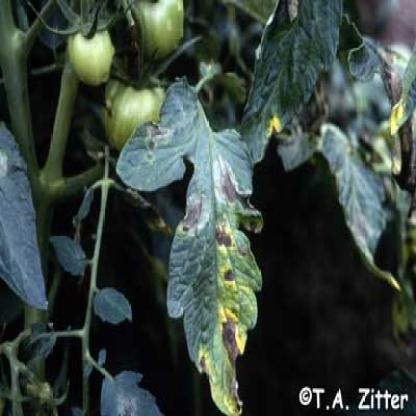

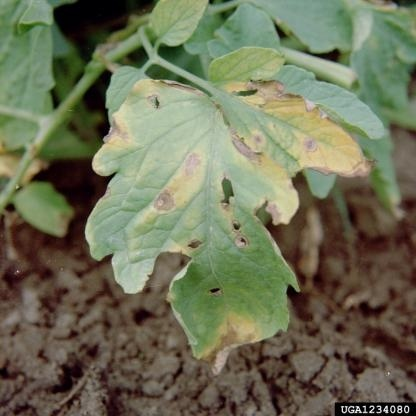

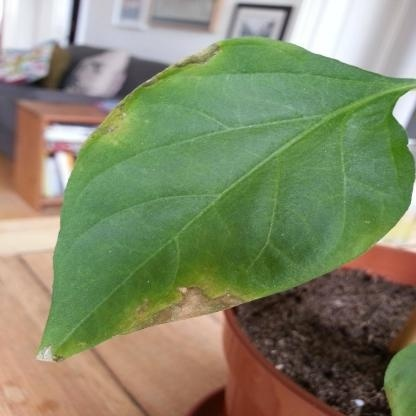

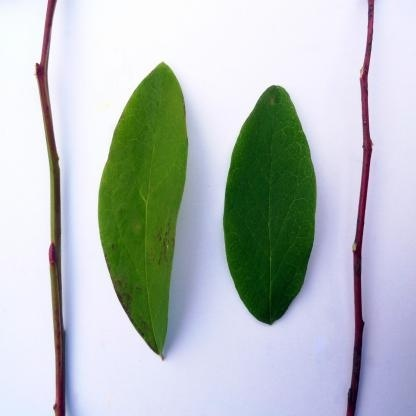

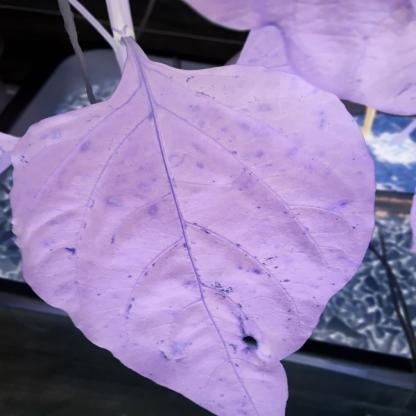

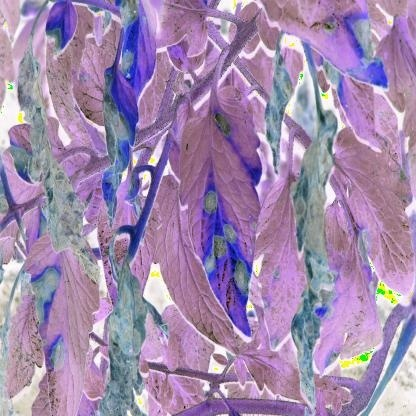

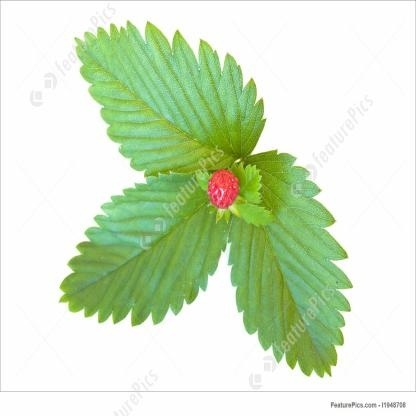

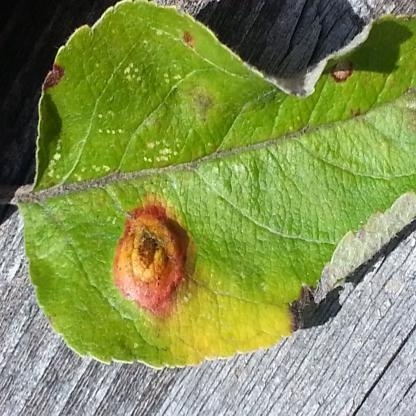

In [66]:
from IPython.display import Image, display
import glob
import os

prediction_images = glob.glob("/content/predictions/*/*.jpg")

print("Total saved prediction images:", len(prediction_images))

# Display first 20 images only, otherwise notebook becomes very heavy
for image_file in prediction_images[:20]:
    display(Image(filename=image_file))

In [67]:
import pandas as pd
from datetime import datetime
from pathlib import Path

records = []

for result in all_dataset_predictions:
    image_name = Path(result.path).name

    if len(result.boxes) == 0:
        records.append({
            "time": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "image": image_name,
            "disease": "No disease detected",
            "confidence": 0
        })

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        disease_name = model.names[class_id]
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        records.append({
            "time": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "image": image_name,
            "disease": disease_name,
            "confidence": round(confidence, 4),
            "confidence_percent": round(confidence * 100, 2),
            "x1": round(x1, 2),
            "y1": round(y1, 2),
            "x2": round(x2, 2),
            "y2": round(y2, 2)
        })

prediction_df = pd.DataFrame(records)

csv_path = "/content/full_dataset_prediction_records.csv"
prediction_df.to_csv(csv_path, index=False)

prediction_df.head()

,time,image,disease,confidence,confidence_percent,x1,y1,x2,y2
0,2026-05-24 07:21:36,Image416_1.jpg,No disease detected,0.0,NaN,NaN,NaN,NaN,NaN
1,2026-05-24 07:21:36,Image416_10.jpg,No disease detected,0.0,NaN,NaN,NaN,NaN,NaN
2,2026-05-24 07:21:36,Image416_100.jpg,No disease detected,0.0,NaN,NaN,NaN,NaN,NaN
3,2026-05-24 07:21:36,Image416_1000.jpg,No disease detected,0.0,NaN,NaN,NaN,NaN,NaN
4,2026-05-24 07:21:36,Image416_1001.jpg,No disease detected,0.0,NaN,NaN,NaN,NaN,NaN


In [68]:
from google.colab import files

files.download(csv_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [69]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename="/content/camera_leaf_image.jpg", quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
            const div = document.createElement('div');
            const button = document.createElement('button');
            button.textContent = 'Capture Photo';
            div.appendChild(button);

            const video = document.createElement('video');
            video.style.display = 'block';

            const stream = await navigator.mediaDevices.getUserMedia({video: true});

            document.body.appendChild(div);
            div.appendChild(video);

            video.srcObject = stream;
            await video.play();

            google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

            await new Promise((resolve) => button.onclick = resolve);

            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;

            canvas.getContext('2d').drawImage(video, 0, 0);

            stream.getVideoTracks()[0].stop();
            div.remove();

            return canvas.toDataURL('image/jpeg', quality);
        }
    ''')

    display(js)

    data = eval_js("takePhoto({})".format(quality))
    binary = b64decode(data.split(",")[1])

    with open(filename, "wb") as f:
        f.write(binary)

    return filename

<IPython.core.display.Javascript object>

Camera image saved at: /content/camera_leaf_image.jpg


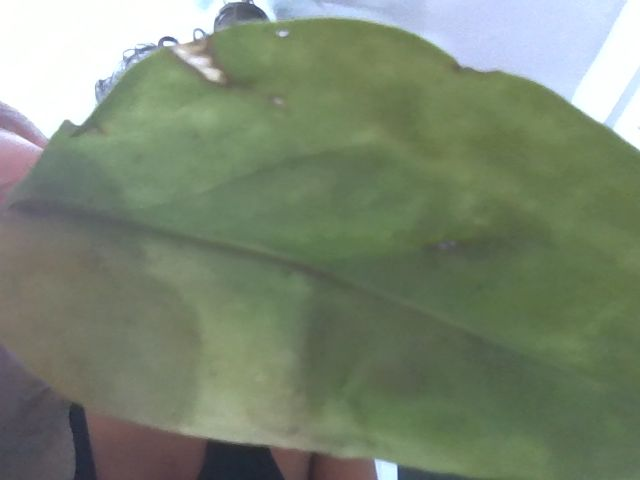

In [71]:
camera_image_path = take_photo()

print("Camera image saved at:", camera_image_path)

display(Image(filename=camera_image_path))

In [72]:
camera_prediction = model.predict(
    source=camera_image_path,
    imgsz=416,
    conf=0.25,
    save=True,
    project="/content/predictions",
    name="camera_result",
    exist_ok=True
)

for result in camera_prediction:
    if len(result.boxes) == 0:
        print("No disease detected.")
    else:
        for box in result.boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])
            disease_name = model.names[class_id]

            print("Detected Disease:", disease_name)
            print("Confidence:", round(confidence * 100, 2), "%")


image 1/1 /content/camera_leaf_image.jpg: 320x416 (no detections), 150.8ms
Speed: 22.2ms preprocess, 150.8ms inference, 1.0ms postprocess per image at shape (1, 3, 320, 416)
Results saved to /content/predictions/camera_result
No disease detected.


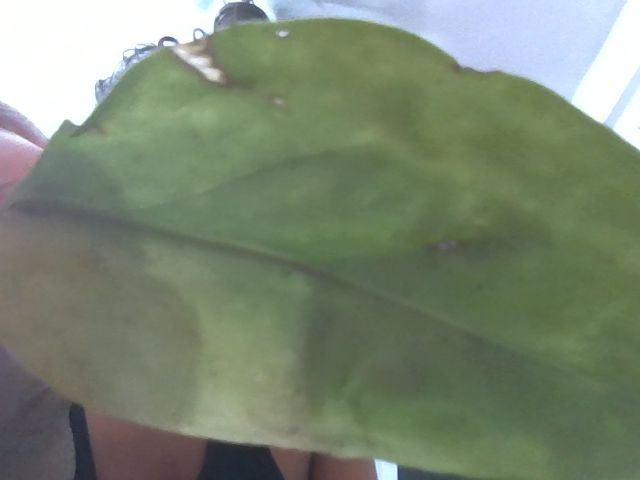

In [73]:
camera_outputs = glob.glob("/content/predictions/camera_result/*")

camera_image_files = [
    file for file in camera_outputs
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
]

if len(camera_image_files) == 0:
    print("No camera prediction image found.")
else:
    latest_camera_result = max(camera_image_files, key=os.path.getctime)
    display(Image(filename=latest_camera_result))

In [74]:
camera_records = []

for result in camera_prediction:
    image_name = Path(result.path).name

    if len(result.boxes) == 0:
        camera_records.append({
            "time": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "image": image_name,
            "disease": "No disease detected",
            "confidence": 0
        })

    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        disease_name = model.names[class_id]

        camera_records.append({
            "time": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "image": image_name,
            "disease": disease_name,
            "confidence": round(confidence, 4),
            "confidence_percent": round(confidence * 100, 2)
        })

camera_df = pd.DataFrame(camera_records)

camera_csv_path = "/content/camera_prediction_records.csv"
camera_df.to_csv(camera_csv_path, index=False)

camera_df

,time,image,disease,confidence
0,2026-05-24 07:25:06,camera_leaf_image.jpg,No disease detected,0


**RECORDING PERMANENTLY**

In [75]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [76]:
from pathlib import Path
import shutil
import json
import pandas as pd
from datetime import datetime

PROJECT_DIR = Path("/content/drive/MyDrive/Plant_Disease_Detection_Project")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_DIR = PROJECT_DIR / "saved_model"
REPORT_DIR = PROJECT_DIR / "training_records"
PREDICTION_DIR = PROJECT_DIR / "prediction_records"

MODEL_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
PREDICTION_DIR.mkdir(exist_ok=True)

print("Project saved at:", PROJECT_DIR)

Project saved at: /content/drive/MyDrive/Plant_Disease_Detection_Project


In [77]:
from pathlib import Path

# Find best trained YOLO model
best_models = list(Path("/content/runs").rglob("best.pt"))

if len(best_models) == 0:
    raise FileNotFoundError("best.pt not found. Train the model first.")

trained_model_path = best_models[-1]

# Save model to Google Drive
saved_model_path = MODEL_DIR / "plant_disease_best.pt"
shutil.copy2(trained_model_path, saved_model_path)

print("Model saved permanently at:")
print(saved_model_path)

Model saved permanently at:
/content/drive/MyDrive/Plant_Disease_Detection_Project/saved_model/plant_disease_best.pt


In [78]:
# Save YOLO training folder
training_run_folders = list(Path("/content/runs/detect").glob("plant_disease_detection*"))

if len(training_run_folders) == 0:
    raise FileNotFoundError("Training folder not found.")

latest_training_folder = training_run_folders[-1]

saved_training_folder = REPORT_DIR / latest_training_folder.name

if saved_training_folder.exists():
    shutil.rmtree(saved_training_folder)

shutil.copytree(latest_training_folder, saved_training_folder)

print("Training records saved at:")
print(saved_training_folder)

Training records saved at:
/content/drive/MyDrive/Plant_Disease_Detection_Project/training_records/plant_disease_detection-4


In [79]:
saved_yaml_path = PROJECT_DIR / "data.yaml"

shutil.copy2(yaml_path, saved_yaml_path)

print("data.yaml saved at:")
print(saved_yaml_path)

data.yaml saved at:
/content/drive/MyDrive/Plant_Disease_Detection_Project/data.yaml


In [80]:
from ultralytics import YOLO

model = YOLO(str(saved_model_path))

metrics = model.val(data=str(yaml_path))

training_summary = {
    "date_time": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "model_path": str(saved_model_path),
    "data_yaml": str(saved_yaml_path),
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map)
}

summary_path = REPORT_DIR / "final_training_summary.json"

with open(summary_path, "w") as f:
    json.dump(training_summary, f, indent=4)

training_summary

Ultralytics 8.4.53 🚀 Python-3.12.13 torch-2.10.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,011,498 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 727.9±223.5 MB/s, size: 57.1 KB)
val: Scanning /content/plant_disease_yolo_clean/labels/val.cache... 463 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 463/463 97.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 2.1s/it 1:01
                   all        463       1708     0.0212      0.412     0.0347     0.0265
       Apple Scab Leaf         17         31      0.018      0.677     0.0203     0.0143
            Apple leaf         16         23     0.0169      0.696     0.0184     0.0137
       Apple rust leaf         16         28     0.0117      0.286    0.00351    0.00229
      Bell_pepper leaf         11         64     0.0262      0.344     0.0133    0.00945
 Bell_pepper leaf spot         12 

{'date_time': '2026-05-24 07:31:06',
 'model_path': '/content/drive/MyDrive/Plant_Disease_Detection_Project/saved_model/plant_disease_best.pt',
 'data_yaml': '/content/drive/MyDrive/Plant_Disease_Detection_Project/data.yaml',
 'precision': 0.021165441711950842,
 'recall': 0.41151902275791624,
 'mAP50': 0.03474225150167497,
 'mAP50_95': 0.026500193381067426}

In [81]:
# If you already created prediction_df from predictions
saved_prediction_csv = PREDICTION_DIR / "plant_disease_prediction_records.csv"

prediction_df.to_csv(saved_prediction_csv, index=False)

print("Prediction records saved at:")
print(saved_prediction_csv)

Prediction records saved at:
/content/drive/MyDrive/Plant_Disease_Detection_Project/prediction_records/plant_disease_prediction_records.csv


In [82]:
from google.colab import drive
from ultralytics import YOLO

drive.mount("/content/drive")

saved_model_path = "/content/drive/MyDrive/Plant_Disease_Detection_Project/saved_model/plant_disease_best.pt"

model = YOLO(saved_model_path)

print("Saved plant disease model loaded successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved plant disease model loaded successfully.


In [83]:
from google.colab import files
from pathlib import Path

uploaded = files.upload()

image_name = list(uploaded.keys())[0]
image_path = Path("/content") / image_name

prediction = model.predict(
    source=str(image_path),
    imgsz=416,
    conf=0.25,
    save=True,
    project="/content/predictions",
    name="saved_model_prediction",
    exist_ok=True
)

print("Prediction completed using saved trained model.")

Saving testImage416_219.jpg to testImage416_219 (2).jpg

image 1/1 /content/testImage416_219 (2).jpg: 416x416 (no detections), 122.8ms
Speed: 3.2ms preprocess, 122.8ms inference, 0.7ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/predictions/saved_model_prediction
Prediction completed using saved trained model.


**streamlit**

In [84]:
!pip install streamlit ultralytics pillow pandas opencv-python -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 34.2 MB/s eta 0:00:00


In [85]:
%%writefile app.py

import streamlit as st
from ultralytics import YOLO
from PIL import Image
import pandas as pd
from datetime import datetime
from pathlib import Path
import tempfile
import os

st.set_page_config(
    page_title="Plant Disease Detection",
    page_icon="🌿",
    layout="wide"
)

st.title("Plant Disease Detection System")
st.write("Upload a plant leaf image or use your camera to detect plant diseases.")

MODEL_PATH = "/content/drive/MyDrive/Plant_Disease_Detection_Project/saved_model/plant_disease_best.pt"

@st.cache_resource
def load_model():
    return YOLO(MODEL_PATH)

model = load_model()

record_file = Path("prediction_records.csv")

def save_prediction_record(records):
    df = pd.DataFrame(records)

    if record_file.exists():
        old_df = pd.read_csv(record_file)
        df = pd.concat([old_df, df], ignore_index=True)

    df.to_csv(record_file, index=False)

def predict_image(image, source_name):
    with tempfile.NamedTemporaryFile(delete=False, suffix=".jpg") as temp_file:
        image.save(temp_file.name)
        temp_path = temp_file.name

    results = model.predict(
        source=temp_path,
        imgsz=416,
        conf=0.25,
        save=False
    )

    prediction_records = []

    result = results[0]
    plotted_image = result.plot()
    plotted_image = Image.fromarray(plotted_image[:, :, ::-1])

    if len(result.boxes) == 0:
        prediction_records.append({
            "time": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "image": source_name,
            "disease": "No disease detected",
            "confidence": 0
        })
    else:
        for box in result.boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])
            disease_name = model.names[class_id]

            prediction_records.append({
                "time": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
                "image": source_name,
                "disease": disease_name,
                "confidence": round(confidence, 4),
                "confidence_percent": round(confidence * 100, 2)
            })

    save_prediction_record(prediction_records)

    os.remove(temp_path)

    return plotted_image, prediction_records

tab1, tab2, tab3 = st.tabs(["Upload Image", "Camera", "Prediction Records"])

with tab1:
    uploaded_files = st.file_uploader(
        "Upload leaf image/images",
        type=["jpg", "jpeg", "png"],
        accept_multiple_files=True
    )

    if uploaded_files:
        for uploaded_file in uploaded_files:
            image = Image.open(uploaded_file).convert("RGB")

            st.subheader(uploaded_file.name)

            col1, col2 = st.columns(2)

            with col1:
                st.image(image, caption="Original Image", use_container_width=True)

            with col2:
                predicted_image, records = predict_image(image, uploaded_file.name)
                st.image(predicted_image, caption="Prediction Result", use_container_width=True)

            st.write(pd.DataFrame(records))

with tab2:
    camera_image = st.camera_input("Capture leaf image")

    if camera_image is not None:
        image = Image.open(camera_image).convert("RGB")

        col1, col2 = st.columns(2)

        with col1:
            st.image(image, caption="Captured Image", use_container_width=True)

        with col2:
            predicted_image, records = predict_image(image, "camera_image.jpg")
            st.image(predicted_image, caption="Camera Prediction", use_container_width=True)

        st.write(pd.DataFrame(records))

with tab3:
    st.subheader("Saved Prediction Records")

    if record_file.exists():
        df = pd.read_csv(record_file)
        st.dataframe(df, use_container_width=True)

        csv_data = df.to_csv(index=False).encode("utf-8")

        st.download_button(
            label="Download Prediction Records CSV",
            data=csv_data,
            file_name="plant_disease_prediction_records.csv",
            mime="text/csv"
        )
    else:
        st.info("No prediction records yet.")

Writing app.py


In [86]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [87]:
from pathlib import Path

model_path = Path("/content/drive/MyDrive/Plant_Disease_Detection_Project/saved_model/plant_disease_best.pt")

print("Model exists:", model_path.exists())
print(model_path)

Model exists: True
/content/drive/MyDrive/Plant_Disease_Detection_Project/saved_model/plant_disease_best.pt


In [88]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 &



2026-05-24 07:50:29.610 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.112.86.46:8501

  Stopping...


In [89]:
import os
import time

# Stop old Streamlit process if already running
!pkill -f streamlit

# Run Streamlit in background and save logs
!nohup streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &

time.sleep(5)

print("Streamlit started. Checking logs:")
!cat streamlit.log

Streamlit started. Checking logs:


2026-05-24 07:57:36.975 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.112.86.46:8501



In [91]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴Need to install the following packages:
localtunnel@2.0.2
Ok to proceed? (y) ^C


In [92]:
!npx --yes localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇your url is: https://common-camels-drum.loca.lt
^C


In [93]:
!curl ipv4.icanhazip.com

136.112.86.46


In [94]:
!pkill -f streamlit
!nohup streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &

In [95]:
!cat streamlit.log



2026-05-24 08:12:18.397 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.112.86.46:8501



In [96]:
!npx --yes localtunnel --port 8501

⠙⠹⠸⠼⠴your url is: https://brave-bats-brake.loca.lt
^C


In [97]:
!curl ipv4.icanhazip.com

136.112.86.46


In [98]:
!pip install pyngrok -q

In [100]:
!pkill -f streamlit
!nohup streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &

In [101]:
!cat streamlit.log



2026-05-24 08:18:51.237 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.112.86.46:8501



In [102]:
!curl http://localhost:8501

<!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2.0 (the "License");
 you may not use this file except in compliance with the License.
 You may obtain a copy of the License at

     http://www.apache.org/licenses/LICENSE-2.0

 Unless required by applicable law or agreed to in writing, software
 distributed under the License is distributed on an "AS IS" BASIS,
 WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
 See the License for the specific language governing permissions and
 limitations under the License.
-->

<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta
      name="viewport"
      content="width=device-width, initial-scale=1, shrink-to-fit=no"
    />
    <link rel="shortcut icon" href="./favicon.png" />
    <link
      rel="preload"
      href="./static/media/SourceSansVF-Upright.ttf.BsWL4Kly.woff2"
      as="font"
      type="font/woff2"
      crossorig

In [103]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

In [104]:
!./cloudflared tunnel --url http://localhost:8501

2026-05-24T08:21:21Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-05-24T08:21:21Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-05-24T08:21:25Z INF +--------------------------------------------------------------------------------------------+
2026-05-24T08:21:25Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-05-24T08:21:25Z INF |  https://dependence-ebooks-retirement-broadcast.tryclo

In [105]:
!cat streamlit.log
!find /content -name "*.pt"



2026-05-24 08:18:51.237 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.112.86.46:8501

2026-05-24 08:22:44.527 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.

image 1/1 /tmp/tmpssxrno37.jpg: 416x416 (no detections), 130.4ms
Speed: 3.2ms preprocess, 130.4ms inference, 2.0ms postprocess per image at shape (1, 3, 416, 416)
2026-05-24 08:22:44.739 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-05-24 08:22:44.834 Please replace `use_container_width` with `width`.

`use_container_width` will be rem

In [ ]:
# from __future__ import annotations

# import csv
# import os
# import tempfile
# from datetime import datetime
# from pathlib import Path

# import pandas as pd
# import streamlit as st
# from PIL import Image
# from ultralytics import YOLO


# BASE_DIR = Path(__file__).resolve().parent
# DEFAULT_MODEL_PATH = BASE_DIR / "models" / "plant_disease_best.pt"
# RECORD_FILE = BASE_DIR / "streamlit_prediction_records.csv"


# st.set_page_config(
#     page_title="Plant Disease Detection",
#     page_icon="PD",
#     layout="wide",
# )


# def find_model_path() -> Path:
#     env_path = os.environ.get("PLANT_MODEL_PATH")
#     if env_path and Path(env_path).exists():
#         return Path(env_path)
#     if DEFAULT_MODEL_PATH.exists():
#         return DEFAULT_MODEL_PATH
#     discovered = list(BASE_DIR.rglob("*.pt"))
#     if discovered:
#         return discovered[0]
#     raise FileNotFoundError(
#         "Model not found. Put plant_disease_best.pt inside "
#         "plant_disease_website/models/ or set PLANT_MODEL_PATH."
#     )


# @st.cache_resource
# def load_model(model_file: str) -> YOLO:
#     return YOLO(model_file)


# def ensure_record_file() -> None:
#     if RECORD_FILE.exists():
#         return
#     with RECORD_FILE.open("w", newline="", encoding="utf-8") as file:
#         writer = csv.DictWriter(
#             file,
#             fieldnames=[
#                 "time",
#                 "image",
#                 "disease",
#                 "confidence",
#                 "confidence_percent",
#                 "x1",
#                 "y1",
#                 "x2",
#                 "y2",
#             ],
#         )
#         writer.writeheader()


# def save_records(records: list[dict]) -> None:
#     ensure_record_file()
#     with RECORD_FILE.open("a", newline="", encoding="utf-8") as file:
#         writer = csv.DictWriter(file, fieldnames=list(records[0].keys()))
#         writer.writerows(records)


# def predict_image(model: YOLO, image: Image.Image, image_name: str, confidence: float) -> tuple[Image.Image, list[dict]]:
#     with tempfile.NamedTemporaryFile(delete=False, suffix=".jpg") as temp_file:
#         image.convert("RGB").save(temp_file.name)
#         temp_path = temp_file.name

#     results = model.predict(source=temp_path, imgsz=416, conf=confidence, save=False)
#     result = results[0]

#     annotated_array = result.plot()
#     annotated_image = Image.fromarray(annotated_array[:, :, ::-1])
#     now = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
#     records: list[dict] = []

#     if len(result.boxes) == 0:
#         records.append(
#             {
#                 "time": now,
#                 "image": image_name,
#                 "disease": "No disease detected",
#                 "confidence": 0,
#                 "confidence_percent": 0,
#                 "x1": "",
#                 "y1": "",
#                 "x2": "",
#                 "y2": "",
#             }
#         )
#     else:
#         for box in result.boxes:
#             class_id = int(box.cls[0])
#             score = float(box.conf[0])
#             disease_name = model.names[class_id]
#             x1, y1, x2, y2 = [round(value, 2) for value in box.xyxy[0].tolist()]
#             records.append(
#                 {
#                     "time": now,
#                     "image": image_name,
#                     "disease": disease_name,
#                     "confidence": round(score, 4),
#                     "confidence_percent": round(score * 100, 2),
#                     "x1": x1,
#                     "y1": y1,
#                     "x2": x2,
#                     "y2": y2,
#                 }
#             )

#     Path(temp_path).unlink(missing_ok=True)
#     save_records(records)
#     return annotated_image, records


# def read_records() -> pd.DataFrame:
#     ensure_record_file()
#     return pd.read_csv(RECORD_FILE)


# st.title("Plant Disease Detection")
# st.caption("YOLO powered leaf scanning app for upload and camera prediction.")

# try:
#     model_path = find_model_path()
#     model = load_model(str(model_path))
#     st.success(f"Model loaded: {model_path}")
# except Exception as exc:
#     st.error(str(exc))
#     st.stop()

# with st.sidebar:
#     st.header("Settings")
#     confidence = st.slider("Confidence threshold", 0.05, 0.95, 0.25, 0.05)
#     st.write("Classes:", len(model.names))
#     st.download_button(
#         "Download prediction records",
#         data=read_records().to_csv(index=False),
#         file_name="plant_disease_prediction_records.csv",
#         mime="text/csv",
#     )

# tab_upload, tab_camera, tab_records = st.tabs(["Upload Images", "Camera", "Records"])

# with tab_upload:
#     uploaded_files = st.file_uploader(
#         "Upload plant leaf images",
#         type=["jpg", "jpeg", "png", "webp"],
#         accept_multiple_files=True,
#     )

#     if uploaded_files:
#         for uploaded_file in uploaded_files:
#             source_image = Image.open(uploaded_file).convert("RGB")
#             annotated_image, records = predict_image(
#                 model=model,
#                 image=source_image,
#                 image_name=uploaded_file.name,
#                 confidence=confidence,
#             )

#             st.subheader(uploaded_file.name)
#             col_original, col_result = st.columns(2)
#             with col_original:
#                 st.image(source_image, caption="Original image", use_container_width=True)
#             with col_result:
#                 st.image(annotated_image, caption="Prediction result", use_container_width=True)
#             st.dataframe(pd.DataFrame(records), use_container_width=True)

# with tab_camera:
#     camera_file = st.camera_input("Capture a plant leaf image")
#     if camera_file is not None:
#         camera_image = Image.open(camera_file).convert("RGB")
#         annotated_image, records = predict_image(
#             model=model,
#             image=camera_image,
#             image_name="camera_leaf.jpg",
#             confidence=confidence,
#         )

#         col_original, col_result = st.columns(2)
#         with col_original:
#             st.image(camera_image, caption="Captured image", use_container_width=True)
#         with col_result:
#             st.image(annotated_image, caption="Prediction result", use_container_width=True)
#         st.dataframe(pd.DataFrame(records), use_container_width=True)

# with tab_records:
#     st.subheader("Prediction history")
#     records_df = read_records()
#     st.dataframe(records_df.tail(100).iloc[::-1], use_container_width=True)

ModuleNotFoundError: No module named 'streamlit'